In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [ ]:
print("========== MP Neuron Logic Gates ==========")

def mp_neuron(inputs, weights, threshold):
    summation = np.dot(inputs, weights)
    return 1 if summation >= threshold else 0

print("\nAND Gate")
and_inputs = [
    [0,0],
    [0,1],
    [1,0],
    [1,1]
]

for x in and_inputs:
    print(x, "->", mp_neuron(x,[1,1],2))

print("\nOR Gate")
for x in and_inputs:
    print(x, "->", mp_neuron(x,[1,1],1))

print("\nNAND Gate")
for x in and_inputs:
    print(x, "->", 1-mp_neuron(x,[1,1],2))

========== MP Neuron Logic Gates ==========

AND Gate
[0, 0] -> 0
[0, 1] -> 0
[1, 0] -> 0
[1, 1] -> 1

OR Gate
[0, 0] -> 0
[0, 1] -> 1
[1, 0] -> 1
[1, 1] -> 1

NAND Gate
[0, 0] -> 1
[0, 1] -> 1
[1, 0] -> 1
[1, 1] -> 0


In [ ]:

df = pd.read_csv("heart_disease_risk_2026.csv")


df = df.drop("patient_id", axis=1)


bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)


df = pd.get_dummies(df, columns=["sex", "chest_pain_type", "smoker_status"], drop_first=True)


X = df.drop("has_heart_disease", axis=1).values
y = df["has_heart_disease"].values


y = np.where(y == 0, -1, 1)


scaler = StandardScaler()
X = scaler.fit_transform(X)

FileNotFoundError: [Errno 2] No such file or directory: 'heart_disease_risk_2026.csv'

In [ ]:
print("========== MP Neuron ==========")

weights = np.ones(X.shape[1])
threshold = 1

predictions = []

for sample in X:
    output = 1 if np.dot(sample, weights) >= threshold else -1
    predictions.append(output)

predictions = np.array(predictions)

accuracy = np.mean(predictions == y)

print("MP Neuron Accuracy:", accuracy)

In [ ]:
import numpy as np

class Perceptron:

    def __init__(self, learning_rate=0.1, epochs=100):
        self.lr = learning_rate
        self.epochs = epochs
        self.weights = None
        self.bias = None
        self.loss_history = []
        self.acc_history = []

    def activation(self, x):
        return np.where(x >= 0, 1, -1)

    def fit(self, X, y):

        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)
        self.bias = 0

        for epoch in range(self.epochs):

            errors = 0

            for idx, x in enumerate(X):

                linear_output = np.dot(x, self.weights) + self.bias
                prediction = self.activation(linear_output)

                if prediction != y[idx]:
                    update = self.lr * y[idx]
                    self.weights += update * x
                    self.bias += update
                    errors += 1

            self.loss_history.append(errors)

            predictions = self.predict(X)
            accuracy = np.mean(predictions == y)
            self.acc_history.append(accuracy)

            if errors == 0:
                print(f"Converged after {epoch+1} epochs")
                break

    def predict(self, X):
        linear_output = np.dot(X, self.weights) + self.bias
        return self.activation(linear_output)

In [ ]:
perceptron = Perceptron(learning_rate=0.1, epochs=100)

perceptron.fit(X, y)

pred = perceptron.predict(X)

accuracy = np.mean(pred == y)

print("Training Accuracy:", accuracy)

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Use only first two features
X_plot = X[:, :2]

# Train perceptron
model = Perceptron(learning_rate=0.1, epochs=50)
model.fit(X_plot, y)

# Create meshgrid
x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Predict on grid
grid = np.c_[xx.ravel(), yy.ravel()]
Z = model.predict(grid)
Z = Z.reshape(xx.shape)

# Plot
plt.figure(figsize=(7,5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
plt.scatter(X_plot[:,0], X_plot[:,1], c=y, edgecolors='k', cmap=plt.cm.coolwarm)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Perceptron Decision Boundary")
plt.show()

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.plot(perceptron.loss_history, marker='o')
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Misclassified Samples")
plt.grid(True)
plt.show()

In [ ]:
plt.figure(figsize=(6,4))
plt.plot(perceptron.acc_history, marker='o')
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.ylim(0,1.05)
plt.grid(True)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *

# Load dataset
data = load_breast_cancer()
X, y = data.data, data.target

# Split and Scale
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Train Logistic Regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:,1]

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC :", roc_auc_score(y_test, y_prob))
print("\nConfusion Matrix\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report\n", classification_report(y_test, y_pred))

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.plot(fpr, tpr)
plt.plot([0,1],[0,1],'--')
plt.title("ROC Curve")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.show()

# Top 5 Features
coef = pd.Series(model.coef_[0], index=data.feature_names)
coef.abs().nlargest(5).plot(kind="bar")
plt.title("Top 5 Features")
plt.show()

# Sample Predictions
print("\nSample Predictions")
print(pd.DataFrame({
    "Actual": y_test[:5],
    "Predicted": y_pred[:5],
    "Probability": y_prob[:5].round(3)
}))

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical


iris = load_iris()
X, y = iris.data, iris.target


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)


scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

model = Sequential([
    Dense(16, activation='relu', input_shape=(4,)),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])


history = model.fit(
    X_train, y_train,
    epochs=50,
    validation_split=0.2,
    verbose=0
)


loss, acc = model.evaluate(X_test, y_test, verbose=0)
print("Test Accuracy:", acc)

y_pred = np.argmax(model.predict(X_test), axis=1)
y_true = np.argmax(y_test, axis=1)

print("\nConfusion Matrix")
print(confusion_matrix(y_true, y_pred))

print("\nClassification Report")
print(classification_report(y_true, y_pred))

print("Training Accuracy :", history.history['accuracy'][-1])
print("Validation Accuracy :", history.history['val_accuracy'][-1])
print("Training Loss :", history.history['loss'][-1])
print("Validation Loss :", history.history['val_loss'][-1])

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.legend(['Train','Validation'])
plt.title("Accuracy")
plt.show()

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend(['Train','Validation'])
plt.title("Loss")
plt.show()

In [ ]:
# Exp 4
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error


np.random.seed(42)
X = 2*np.random.rand(200,1)
y = 4 + 3*X[:,0] + np.random.randn(200)*0.8

Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=.2,random_state=42)
s = StandardScaler()
Xtr,Xte = s.fit_transform(Xtr),s.transform(Xte)
Xtr = np.c_[np.ones(len(Xtr)),Xtr]
Xte = np.c_[np.ones(len(Xte)),Xte]


w = np.zeros(2)
lr,epochs = .01,100
loss = []

for e in range(epochs):
    for i in np.random.permutation(len(Xtr)):
        err = Xtr[i]@w-ytr[i]
        w -= lr*err*Xtr[i]
    loss.append(np.mean((Xtr@w-ytr)**2))

ps = Xte@w


wn = np.linalg.inv(Xtr.T@Xtr)@Xtr.T@ytr
pn = Xte@wn


def CI(y,p):
    c=n=0
    for i in range(len(y)):
        for j in range(i+1,len(y)):
            if y[i] != y[j]:
                n += 1
                c += (y[i]-y[j])*(p[i]-p[j]) > 0
    return c/n


for name,p in [("SGD",ps),("Normal Equation",pn)]:
    mse = mean_squared_error(yte,p)
    print(name,": MSE =",mse," RMSE =",np.sqrt(mse)," CI =",CI(yte,p))


i = np.argsort(Xte[:,1])
plt.scatter(Xte[:,1],yte,label="Actual")
plt.plot(Xte[i,1],ps[i],label="SGD")
plt.plot(Xte[i,1],pn[i],"--",label="Normal Equation")
plt.xlabel("Feature"); plt.ylabel("Target")
plt.title("Regression Line vs Actual Data")
plt.legend(); plt.show()


plt.plot(loss)
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.title("SGD Training Loss")
plt.show()

In [ ]:
#Exp 5
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error


np.random.seed(42)
X = 2*np.random.rand(200,1)
y = 4 + 3*X[:,0] + np.random.randn(200)*0.8

Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=.2,random_state=42)
s = StandardScaler()
Xtr,Xte = s.fit_transform(Xtr),s.transform(Xte)
Xtr = np.c_[np.ones(len(Xtr)),Xtr]
Xte = np.c_[np.ones(len(Xte)),Xte]

lr, epochs, batch = .01, 100, 32


def train(bs):
    w = np.zeros(2)
    mse, mae = [], []
    for e in range(epochs):
        idx = np.random.permutation(len(Xtr))
        for i in range(0,len(Xtr),bs):
            j = idx[i:i+bs]
            err = Xtr[j]@w-ytr[j]
            w -= lr * Xtr[j].T@err / len(j)
        p = Xtr@w
        mse.append(mean_squared_error(ytr,p))
        mae.append(mean_absolute_error(ytr,p))
    return w,mse,mae


w_sgd,mse_sgd,mae_sgd = train(1)
w_mb,mse_mb,mae_mb = train(32)


for name,w in [("SGD",w_sgd),("Mini-Batch SGD",w_mb)]:
    p = Xte@w
    print(name,": MSE =",mean_squared_error(yte,p),
          " RMSE =",np.sqrt(mean_squared_error(yte,p)),
          " MAE =",mean_absolute_error(yte,p))


plt.plot(mse_sgd,label="SGD")
plt.plot(mse_mb,label="Mini-Batch SGD")
plt.xlabel("Epoch"); plt.ylabel("MSE")
plt.title("MSE vs Epochs")
plt.legend(); plt.show()


plt.plot(mae_sgd,label="SGD")
plt.plot(mae_mb,label="Mini-Batch SGD")
plt.xlabel("Epoch"); plt.ylabel("MAE")
plt.title("MAE vs Epochs")
plt.legend(); plt.show()

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt

# Load Fashion MNIST
(x, y), (xt, yt) = tf.keras.datasets.fashion_mnist.load_data()

# Small subset
x, y = x[:3000], y[:3000]

# Normalize
x, xt = x / 255.0, xt / 255.0
x, xt = x[..., None], xt[..., None]

# CNN function
def cnn(l2=0, dropout=0, augment=False):

    model = tf.keras.Sequential()
    model.add(tf.keras.Input(shape=(28, 28, 1)))

    if augment:
        model.add(tf.keras.layers.RandomRotation(0.1))

    model.add(tf.keras.layers.Conv2D(
        32, 3, activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(l2) if l2 else None
    ))
    model.add(tf.keras.layers.MaxPooling2D())
    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense(
        64, activation='relu',
        kernel_regularizer=tf.keras.regularizers.l2(l2) if l2 else None
    ))
    model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model


# Five models
models = {
    "Baseline": cnn(),
    "L2": cnn(l2=0.001),
    "Dropout": cnn(dropout=0.5),
    "Augmentation": cnn(augment=True),
    "Early Stop": cnn()
}

histories = {}

# Train
for name, model in models.items():

    callback = []
    if name == "Early Stop":
        callback = [
            tf.keras.callbacks.EarlyStopping(
                monitor='val_loss',
                patience=2,
                restore_best_weights=True
            )
        ]

    histories[name] = model.fit(
        x, y,
        epochs=15,
        batch_size=64,
        validation_split=0.2,
        callbacks=callback,
        verbose=0
    )

    accuracy = model.evaluate(xt, yt, verbose=0)[1]
    print(name, "Test Accuracy:", round(accuracy, 4))


# Training accuracy graph
plt.figure(figsize=(8,5))
for name, h in histories.items():
    plt.plot(h.history['accuracy'], label=name)

plt.xlabel("Epoch")
plt.ylabel("Training Accuracy")
plt.title("Training Accuracy")
plt.legend()
plt.show()


# Validation accuracy graph
plt.figure(figsize=(8,5))
for name, h in histories.items():
    plt.plot(h.history['val_accuracy'], label=name)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Validation Accuracy")
plt.legend()
plt.show()

In [ ]:
#EXP 7
!pip install gensim nltk -q

import nltk
nltk.download('brown')

from nltk.corpus import brown
from gensim.models import Word2Vec

sentences = brown.sents()


model = Word2Vec(
    sentences,
    vector_size=100,
    window=5,
    min_count=2,
    sg=1,
    workers=4,
    epochs=10
)


word = "government"
print("Nearest words to", word)
print(model.wv.most_similar(word, topn=5))

try:
    print("\nAnalogy result:")
    print(model.wv.most_similar(
        positive=["king", "woman"],
        negative=["man"],
        topn=5
    ))
except KeyError:
    print("Some analogy words are not in the corpus.")


In [ ]:
!pip install 'git+https://github.com/facebookresearch/detectron2.git'
import os, cv2, torch, requests
import matplotlib.pyplot as plt
from detectron2.config import get_cfg
from detectron2 import model_zoo
from detectron2.engine import DefaultPredictor
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog

cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file(
    "COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml"))
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
    "COCO-Detection/faster_rcnn_R_50_FPN_3x.yaml")
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
cfg.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

img = "sample_image.jpg"
url = "https://hips.hearstapps.com/clv.h-cdn.co/assets/16/18/gettyimages-586890581.jpg?crop=0.668xw:1.00xh;0.219xw,0"

if not os.path.exists(img):
    r = requests.get(url)
    open(img, "wb").write(r.content)

image = cv2.imread(img)
predictor = DefaultPredictor(cfg)
outputs = predictor(image)

v = Visualizer(
    image[:, :, ::-1],
    MetadataCatalog.get(cfg.DATASETS.TRAIN[0]),
    scale=1.2
)

result = v.draw_instance_predictions(
    outputs["instances"].to("cpu")
).get_image()

cv2.imwrite("detection_result.jpg", result[:, :, ::-1])

plt.figure(figsize=(10, 6))
plt.imshow(result)
plt.axis("off")
plt.show()

# Detection confidence values
scores = outputs["instances"].scores.cpu().numpy()

print("Number of detected objects:", len(scores))
print("Detection confidence values:", scores)
print("Average detection confidence:", scores.mean())

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.1CKVX0_4.0.1/cats_vs_dogs-train.tfrecord-[0-9][0-9…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 31s 197ms/step - accuracy: 0.9545 - loss: 0.1944 - val_accuracy: 0.9812 - val_loss: 0.0632
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 23s 186ms/step - accuracy: 0.9827 - loss: 0.0569 - val_accuracy: 0.9812 - val_loss: 0.0962
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 27s 212ms/step - accuracy: 0.9868 - loss: 0.0389 - val_accuracy: 0.9812 - val_loss: 0.0790
25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 184ms/step - accuracy: 0.9812 - loss: 0.0790
Validation Accuracy: 98.12 %


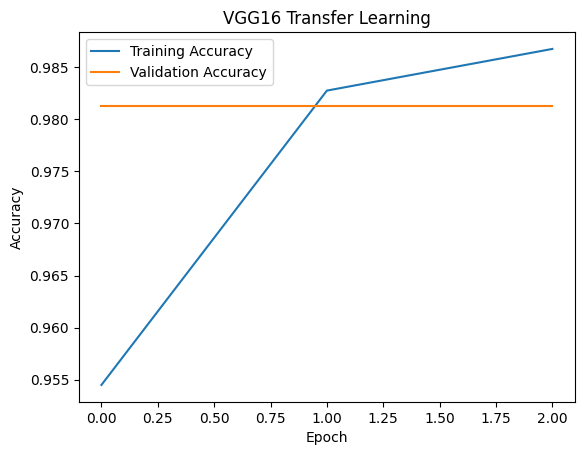

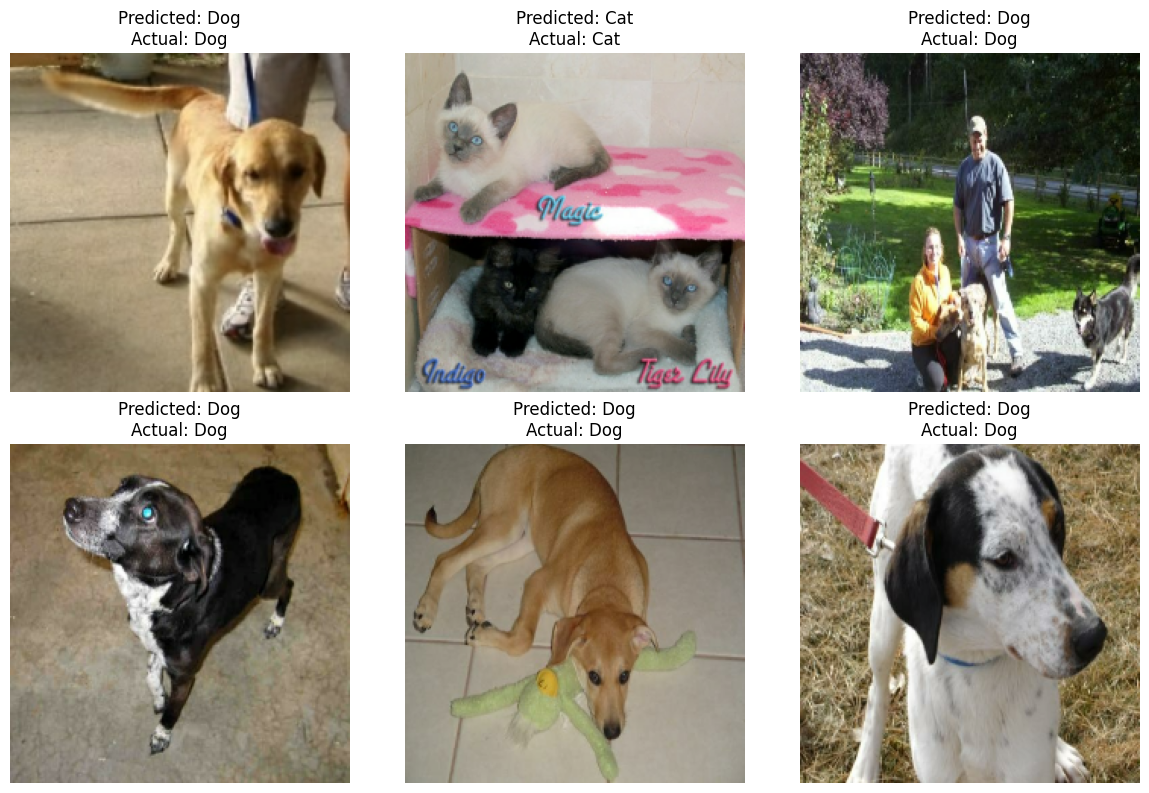

In [ ]:
!pip install -q importlib_resources
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model

(ds_train, ds_val), info = tfds.load(
    'cats_vs_dogs',
    split=['train[:80%]', 'train[80%:]'],
    as_supervised=True,
    with_info=True
)

def resize(image, label):
    image = tf.image.resize(image, (224, 224))
    image = preprocess_input(image)
    return image, label

train = ds_train.take(4000).map(resize).batch(32).prefetch(tf.data.AUTOTUNE)
val = ds_val.take(800).map(resize).batch(32).prefetch(tf.data.AUTOTUNE)

base = VGG16(weights='imagenet', include_top=False,
             input_shape=(224, 224, 3))
base.trainable = False

z = GlobalAveragePooling2D()(base.output)
z = Dense(128, activation='relu')(z)
out = Dense(1, activation='sigmoid')(z)

model = Model(base.input, out)

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

history = model.fit(train, epochs=3, validation_data=val)

loss, accuracy = model.evaluate(val)
print("Validation Accuracy:", round(accuracy * 100, 2), "%")

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('VGG16 Transfer Learning')
plt.legend()
plt.show()

class_names = ['Cat', 'Dog']

for images, labels in val.take(1):
    predictions = model.predict(images, verbose=0)

    plt.figure(figsize=(12, 8))

    for i in range(min(6, len(images))):
        pred = int(predictions[i][0] >= 0.5)
        actual = int(labels[i].numpy())

        img = images[i].numpy()
        img = img + [103.939, 116.779, 123.68]
        img = img[:, :, ::-1].clip(0, 255).astype('uint8')

        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(f"Predicted: {class_names[pred]}\nActual: {class_names[actual]}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 33s 233ms/step - accuracy: 0.9592 - loss: 0.1573 - val_accuracy: 0.9750 - val_loss: 0.0920
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 35s 200ms/step - accuracy: 0.9843 - loss: 0.0473 - val_accuracy: 0.9812 - val_loss: 0.0712
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 27s 211ms/step - accuracy: 0.9923 - loss: 0.0237 - val_accuracy: 0.9837 - val_loss: 0.0642
Test Accuracy: 98.37 %


Text(0.5, 0, 'Epoch')

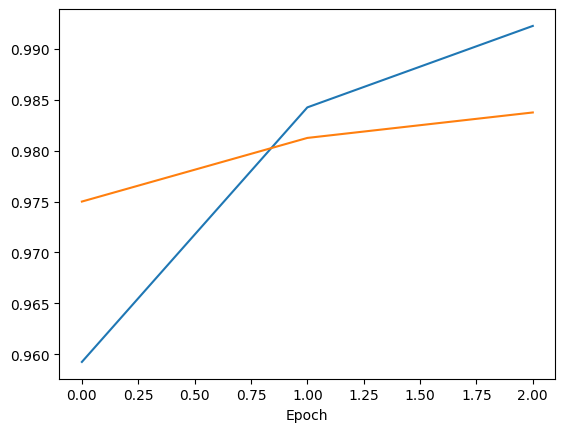

In [ ]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model

a, b = tfds.load('cats_vs_dogs',
    split=['train[:80%]', 'train[80%:]'], as_supervised=True)

def prep(x, y):
    return preprocess_input(tf.image.resize(x, (224,224))), y

train = a.take(4000).map(prep).batch(32).prefetch(tf.data.AUTOTUNE)
test = b.take(800).map(prep).batch(32).prefetch(tf.data.AUTOTUNE)

base = VGG16(weights='imagenet', include_top=False,
             input_shape=(224,224,3))
base.trainable = False

x = GlobalAveragePooling2D()(base.output)
x = Dense(128, activation='relu')(x)
out = Dense(1, activation='sigmoid')(x)
model = Model(base.input, out)

model.compile(optimizer='adam', loss='binary_crossentropy',
              metrics=['accuracy'])

h = model.fit(train, epochs=3, validation_data=test)

print("Test Accuracy:", round(model.evaluate(test, verbose=0)[1]*100, 2), "%")

plt.plot(h.history['accuracy'], label='Training')
plt.plot(h.history['val_accuracy'], label='Validation')
plt.xlabel('Epoch')

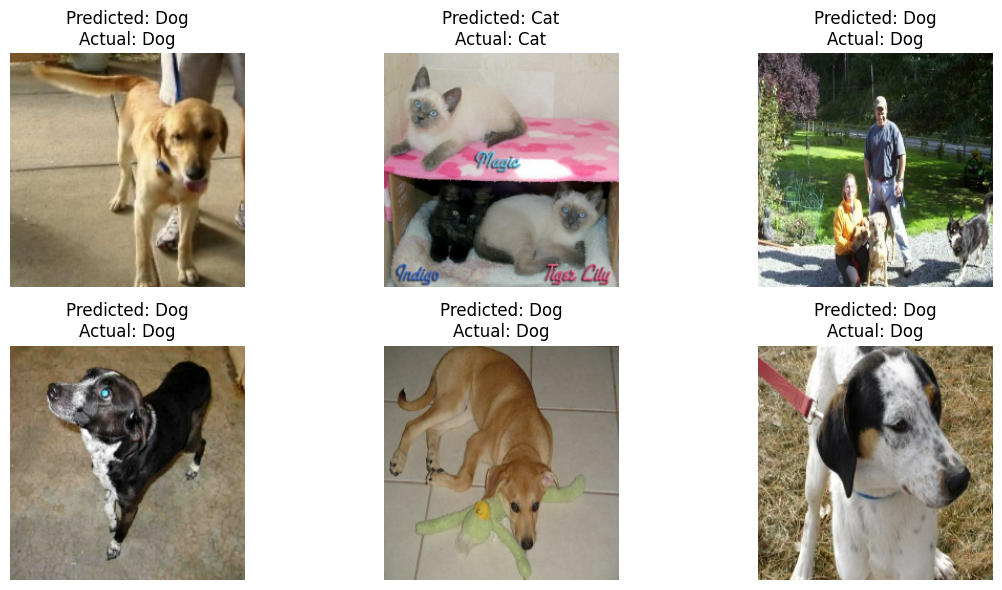

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

for images, labels in test.take(1):
    pred = model.predict(images, verbose=0)

    plt.figure(figsize=(12, 6))

    for i in range(6):
        img = images[i].numpy()
        img = (img + [103.939, 116.779, 123.68])[:, :, ::-1]
        img = np.clip(img, 0, 255).astype('uint8')

        p = "Dog" if pred[i][0] >= 0.5 else "Cat"
        actual = "Dog" if int(labels[i]) == 1 else "Cat"

        plt.subplot(2, 3, i + 1)
        plt.imshow(img)
        plt.title(f"Predicted: {p}\nActual: {actual}")
        plt.axis('off')

    plt.tight_layout()
    plt.show()

Epoch 1/20
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.2826 - loss: 2.6331 - val_accuracy: 0.3144 - val_loss: 2.4196
Epoch 2/20
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.3647 - loss: 2.2048 - val_accuracy: 0.3644 - val_loss: 2.2246
Epoch 3/20
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.3947 - loss: 2.0787 - val_accuracy: 0.3953 - val_loss: 2.1098
Epoch 4/20
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.4143 - loss: 1.9984 - val_accuracy: 0.4107 - val_loss: 2.0499
Epoch 5/20
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.4282 - loss: 1.9417 - val_accuracy: 0.4267 - val_loss: 1.9923
Epoch 6/20
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.4412 - loss: 1.8968 - val_accuracy: 0.4420 - val_loss: 1.9495
Epoch 7/20
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.4526 - loss: 1.8538 - val_accuracy: 0.4456 - val_loss: 1.9275
Epoch 8/20
1406/1406 ━━━━━━━━━━━━━━━━━━━━ 10s 7ms/step - accuracy: 0.4604 - loss: 

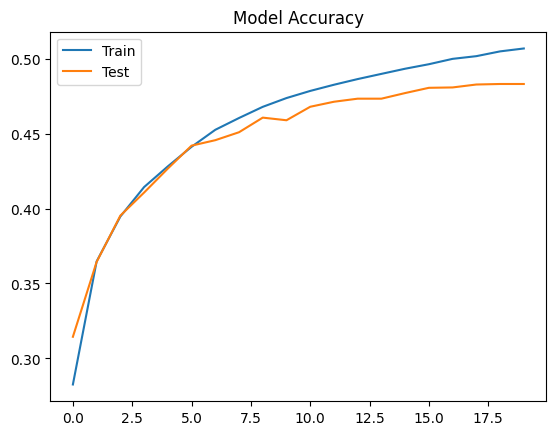

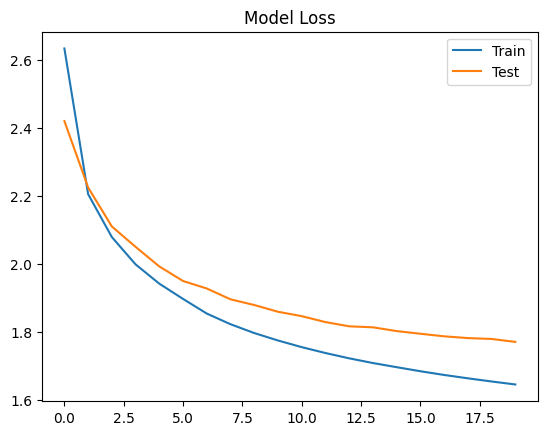

Generated Text:
  be, or not to be, that is the question:
Eutter on hav’d this liting clows; whis,
Thou as ase whilgest diend I nate my blace,
Puvion lie of thou here lie tron and thee,
Who didgenst) at theirds hik stricks thine
Of sing of ank I hads in Pinsest, and de?
    Alo not Insared pronot desself not copack.

CLOWN.
So, and a fast, and imbraladd’s


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import urllib.request

url = "https://www.gutenberg.org/files/100/100-0.txt"
text = urllib.request.urlopen(url).read().decode("utf-8")
text = text.split("*** START OF THE PROJECT GUTENBERG EBOOK")[1]
text = text.split("*** END OF THE PROJECT GUTENBERG EBOOK")[0]
text = text[:200000]

chars = sorted(set(text))
c2i = {c:i for i,c in enumerate(chars)}
i2c = {i:c for c,i in c2i.items()}

n = 40
d = np.array([c2i[c] for c in text])
X = np.array([d[i:i+n] for i in range(len(d)-n)])
y = d[n:]
s = int(0.9*len(X))

m = tf.keras.Sequential([
    tf.keras.layers.Embedding(len(chars), 32),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(len(chars), activation='softmax')
])

m.compile(optimizer='adam',
          loss='sparse_categorical_crossentropy',
          metrics=['accuracy'])

h = m.fit(X[:s], y[:s], epochs=20, batch_size=128,
          validation_data=(X[s:], y[s:]))

print("Train Accuracy:", m.evaluate(X[:s], y[:s], verbose=0)[1]*100, "%")
print("Test Accuracy:", m.evaluate(X[s:], y[s:], verbose=0)[1]*100, "%")

plt.plot(h.history['accuracy'], label='Train')
plt.plot(h.history['val_accuracy'], label='Test')
plt.title('Model Accuracy')
plt.legend()
plt.show()

plt.plot(h.history['loss'], label='Train')
plt.plot(h.history['val_loss'], label='Test')
plt.title('Model Loss')
plt.legend()
plt.show()

seed = "To be, or not to be, that is the question:"
seed = seed[-n:]

for _ in range(300):
    x = np.array([[c2i[c] for c in seed[-n:]]])
    p = m.predict(x, verbose=0)[0]
    seed += i2c[np.random.choice(len(chars), p=p)]

print("Generated Text:\n", seed)

Epoch 1/30
703/703 ━━━━━━━━━━━━━━━━━━━━ 22s 15ms/step - accuracy: 0.2502 - loss: 2.8016 - val_accuracy: 0.2835 - val_loss: 2.5354
Epoch 2/30
703/703 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.3432 - loss: 2.2903 - val_accuracy: 0.3324 - val_loss: 2.3291
Epoch 3/30
703/703 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.3789 - loss: 2.1511 - val_accuracy: 0.3671 - val_loss: 2.2083
Epoch 4/30
703/703 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.3987 - loss: 2.0668 - val_accuracy: 0.3846 - val_loss: 2.1390
Epoch 5/30
703/703 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.4122 - loss: 2.0092 - val_accuracy: 0.4036 - val_loss: 2.0731
Epoch 6/30
703/703 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4236 - loss: 1.9627 - val_accuracy: 0.4146 - val_loss: 2.0294
Epoch 7/30
703/703 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4346 - loss: 1.9194 - val_accuracy: 0.4238 - val_loss: 1.9945
Epoch 8/30
703/703 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4423 - loss: 1.8862 - val_accuracy:

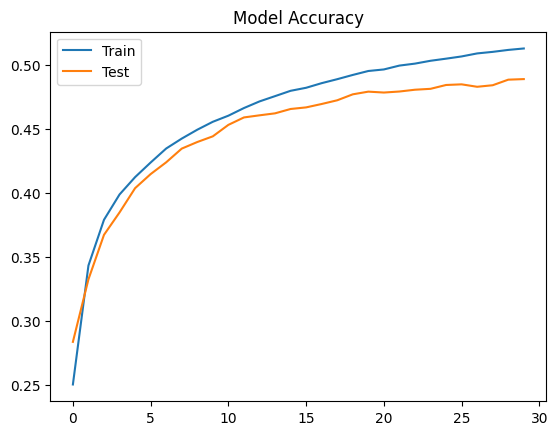

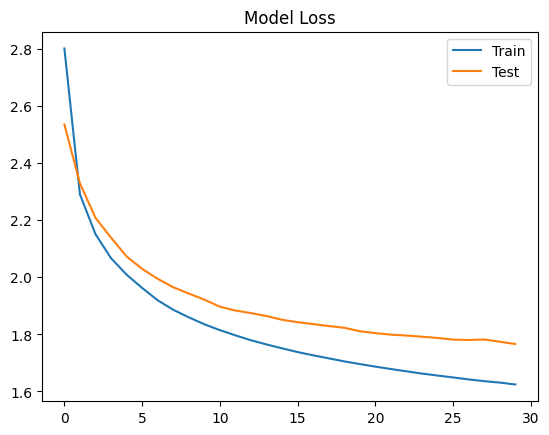

Generated Text:
  be, or not to be, that is the question:
So the pudds for my though od she cliarts
For I kine inming ow, but she wing, (The kefer,
  So pratent, do in shalts of I by dimpar apare what wleasgry should chusss nems fald and hat,
Buty than thy hand?—Well, but my war, my mide bidictances conmsedd.
By vires to do comfarnomber trof swittice,
No 


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import urllib.request

url = "https://www.gutenberg.org/files/100/100-0.txt"
text = urllib.request.urlopen(url).read().decode("utf-8")
text = text.split("*** START OF THE PROJECT GUTENBERG EBOOK")[1]
text = text.split("*** END OF THE PROJECT GUTENBERG EBOOK")[0]
text = text[:200000]

chars = sorted(set(text))
c2i = {c:i for i,c in enumerate(chars)}
i2c = {i:c for c,i in c2i.items()}

n = 40
d = np.array([c2i[c] for c in text])
X = np.array([d[i:i+n] for i in range(len(d)-n)])
y = d[n:]
s = int(0.9*len(X))

m = tf.keras.Sequential([
    tf.keras.layers.Embedding(len(chars), 32),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(len(chars), activation='softmax')
])

m.compile(optimizer='adam',
          loss='sparse_categorical_crossentropy',
          metrics=['accuracy'])

h = m.fit(X[:s], y[:s], epochs=30, batch_size=256,
          validation_data=(X[s:], y[s:]))

print("Train Accuracy:", m.evaluate(X[:s], y[:s], verbose=0)[1]*100, "%")
print("Test Accuracy:", m.evaluate(X[s:], y[s:], verbose=0)[1]*100, "%")

plt.plot(h.history['accuracy'], label='Train')
plt.plot(h.history['val_accuracy'], label='Test')
plt.title('Model Accuracy')
plt.legend()
plt.show()

plt.plot(h.history['loss'], label='Train')
plt.plot(h.history['val_loss'], label='Test')
plt.title('Model Loss')
plt.legend()
plt.show()

seed = "To be, or not to be, that is the question:"
seed = seed[-n:]

for _ in range(300):
    x = np.array([[c2i[c] for c in seed[-n:]]])
    p = m.predict(x, verbose=0)[0]
    seed += i2c[np.random.choice(len(chars), p=p)]

print("Generated Text:\n", seed)

In [ ]:
!pip install tensorflow datasets scikit-learn matplotlib

dataset_infos.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  281kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  259kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

Epoch 1/5
198/198 ━━━━━━━━━━━━━━━━━━━━ 21s 36ms/step - accuracy: 0.8242 - loss: 0.7663 - val_accuracy: 0.8886 - val_loss: 0.3974
Epoch 2/5
198/198 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.8982 - loss: 0.3220 - val_accuracy: 0.9269 - val_loss: 0.2597
Epoch 3/5
198/198 ━━━━━━━━━━━━━━━━━━━━ 6s 29ms/step - accuracy: 0.9551 - loss: 0.1554 - val_accuracy: 0.9490 - val_loss: 0.1984
Epoch 4/5
198/198 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.9824 - loss: 0.0758 - val_accuracy: 0.9554 - val_loss: 0.1775
Epoch 5/5
198/198 ━━━━━━━━━━━━━━━━━━━━ 7s 34ms/step - accuracy: 0.9910 - loss: 0.0425 - val_accuracy: 0.9551 - val_loss: 0.1686
108/108 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step
F1 Score: 0.7850634546770674


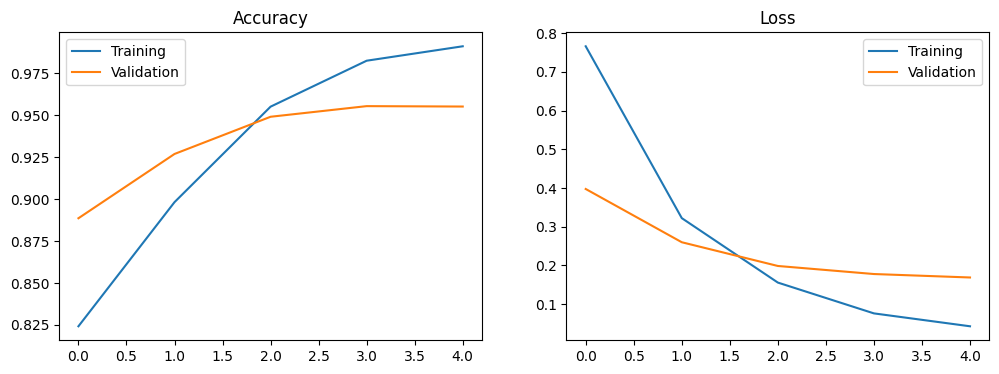

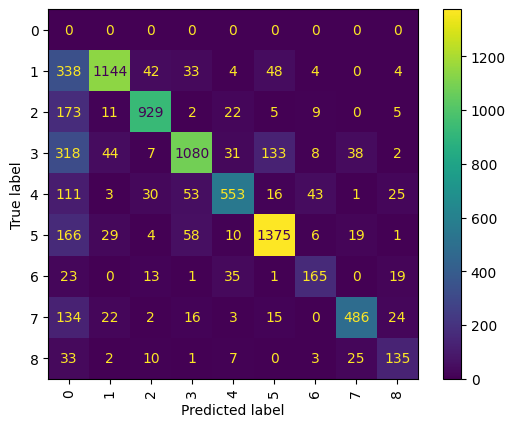

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from datasets import load_dataset
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

data = load_dataset("lhoestq/conll2003")
train, test = data["train"], data["test"]

words = list(set(w for s in train["tokens"] for w in s))
tags = list(set(t for s in train["ner_tags"] for t in s))

word2idx = {w:i+2 for i,w in enumerate(words)}
tag2idx = {t:i for i,t in enumerate(tags)}

def prepare(ds):
    X = [[word2idx.get(w,1) for w in s] for s in ds["tokens"]]
    y = [[tag2idx[t] for t in s] for s in ds["ner_tags"]]
    return pad_sequences(X, padding="post"), pad_sequences(y, padding="post")

X_train, y_train = prepare(train)
X_test, y_test = prepare(test)

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(len(word2idx)+2, 64, mask_zero=True),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=True)),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(tags), activation="softmax"))
])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(X_train, y_train, epochs=5, batch_size=64,
                    validation_split=0.1)

pred = np.argmax(model.predict(X_test), axis=-1)
mask = y_test != 0

print("F1 Score:", f1_score(y_test[mask], pred[mask], average="weighted"))

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Loss")
plt.legend()
plt.show()

cm = confusion_matrix(y_test[mask], pred[mask])
ConfusionMatrixDisplay(cm, display_labels=tags).plot(xticks_rotation=90)
plt.show()

/usr/local/lib/python3.13/dist-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
/usr/local/lib/python3.13/dist-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
/usr/local/lib/python3.13/dist-packages/nltk/translate/bleu_score.py:577: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_

BLEU Score: 7.31380102804205e-232
<start> hello <end> -> bonjour
<start> how are you <end> -> comment allez vous
<start> i am fine <end> -> je vais bien
<start> thank you <end> -> merci


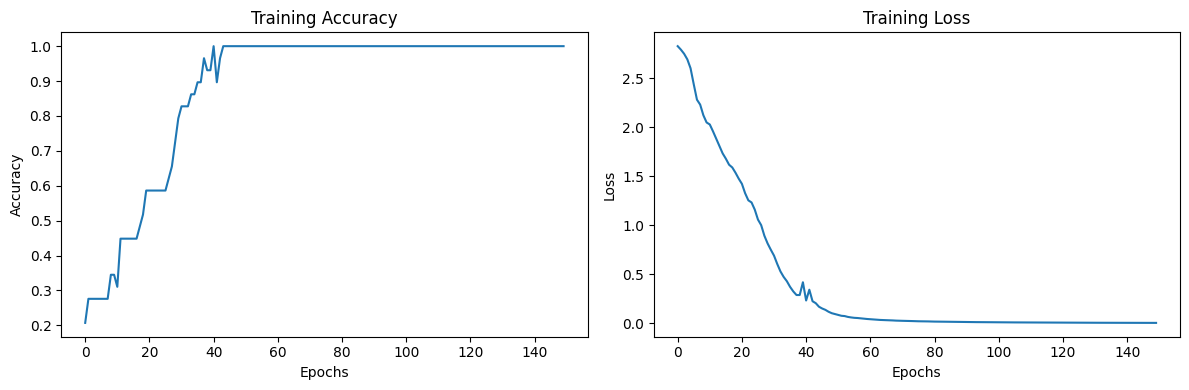

In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from nltk.translate.bleu_score import corpus_bleu

en = ["hello", "how are you", "i am fine", "thank you",
      "good morning", "i love you", "good night", "see you"]

fr = ["bonjour", "comment allez vous", "je vais bien", "merci",
      "bonjour", "je t aime", "bonne nuit", "a bientot"]

en = ["<start> " + s + " <end>" for s in en]
fr = ["<start> " + s + " <end>" for s in fr]

ev = tf.keras.preprocessing.text.Tokenizer(filters='')
fv = tf.keras.preprocessing.text.Tokenizer(filters='')
ev.fit_on_texts(en)
fv.fit_on_texts(fr)

X = tf.keras.preprocessing.sequence.pad_sequences(
    ev.texts_to_sequences(en), padding="post")

Y = tf.keras.preprocessing.sequence.pad_sequences(
    fv.texts_to_sequences(fr), padding="post")


enc_in = tf.keras.Input(shape=(None,))
e = tf.keras.layers.Embedding(len(ev.word_index)+1, 64, mask_zero=True)(enc_in)

enc_out, fh, fc, bh, bc = tf.keras.layers.Bidirectional(
    tf.keras.layers.LSTM(64, return_sequences=True, return_state=True)
)(e)

h = tf.keras.layers.Concatenate()([fh, bh])
c = tf.keras.layers.Concatenate()([fc, bc])


dec_in = tf.keras.Input(shape=(None,))
d = tf.keras.layers.Embedding(len(fv.word_index)+1, 128, mask_zero=True)(dec_in)

lstm = tf.keras.layers.LSTM(128, return_sequences=True, return_state=True)
do, _, _ = lstm(d, initial_state=[h, c])

att = tf.keras.layers.AdditiveAttention()([do, enc_out])

out = tf.keras.layers.Dense(len(fv.word_index)+1, activation="softmax")(
    tf.keras.layers.Concatenate()([do, att]))

model = tf.keras.Model([enc_in, dec_in], out)

model.compile(optimizer="adam",
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(
    [X, Y[:, :-1]], Y[:, 1:, None],
    epochs=150, batch_size=2, verbose=0
)


def translate(sentence):
    x = tf.keras.preprocessing.sequence.pad_sequences(
        ev.texts_to_sequences([sentence]),
        maxlen=X.shape[1], padding="post")

    result = ["<start>"]

    for _ in range(10):
        seq = fv.texts_to_sequences([" ".join(result)])
        y = tf.keras.preprocessing.sequence.pad_sequences(
            seq, maxlen=Y.shape[1], padding="post")

        p = model.predict([x, y], verbose=0)[0, len(result)-1]
        word = fv.index_word.get(np.argmax(p), "<end>")

        if word == "<end>":
            break

        result.append(word)

    return " ".join(result[1:])


actual, predicted = [], []

for a, b in zip(en, fr):
    actual.append([b.split()[1:-1]])
    predicted.append(translate(a))

print("BLEU Score:", corpus_bleu(actual, predicted))

for a in en[:4]:
    print(a, "->", translate(a))


plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"])
plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"])
plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1: Loss=0.1053, Accuracy=0.0960
Epoch 2: Loss=0.0973, Accuracy=0.0743
Epoch 3: Loss=0.0924, Accuracy=0.1283
Epoch 4: Loss=0.0873, Accuracy=0.0797
Epoch 5: Loss=0.0811, Accuracy=0.0867
Epoch 6: Loss=0.0768, Accuracy=0.0667
Epoch 7: Loss=0.0750, Accuracy=0.1237
Epoch 8: Loss=0.0738, Accuracy=0.1337
Epoch 9: Loss=0.0726, Accuracy=0.0983
Epoch 10: Loss=0.0714, Accuracy=0.0713

Final Accuracy: 0.07133333333333333

Classification Report:
               precision    recall  f1-score   support

           0       0.01      0.01      0.01       300
           1       0.09      0.18      0.12       300
           2       0.00      0.00      0.00       300
           3       0.06      0.04      0.05       300
           4       0.09      0.15      0.11       300
           5       0.25      0.17      0.21 

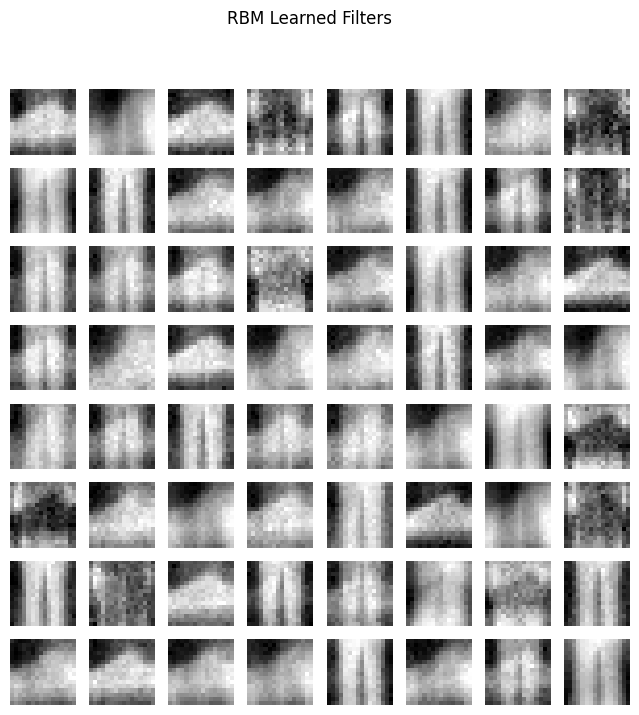

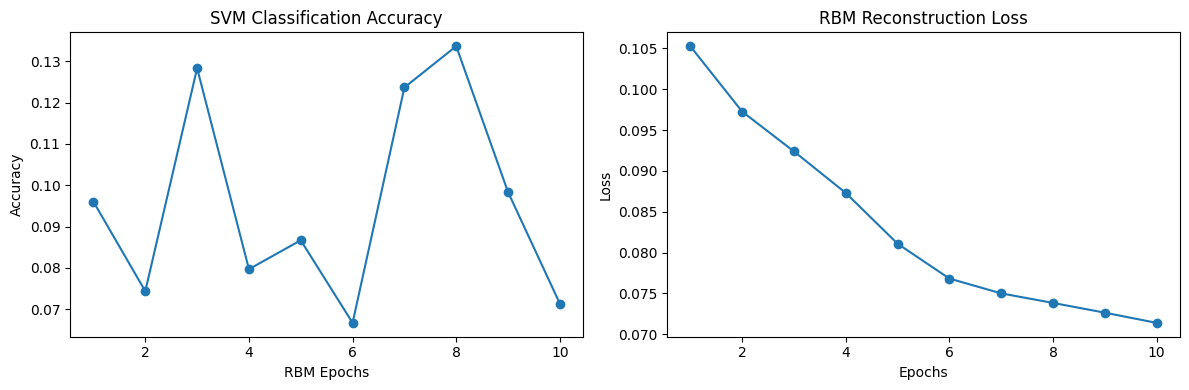

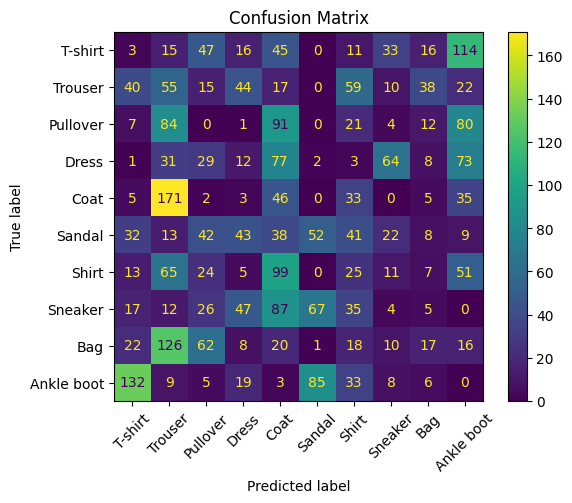

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split


(x, y), (xt, yt) = tf.keras.datasets.fashion_mnist.load_data()


x = x[:, 6:22, 6:22] / 255.0
xt = xt[:, 6:22, 6:22] / 255.0

X = x.reshape(-1, 256)
Xt = xt.reshape(-1, 256)

X_train, _, y_train, _ = train_test_split(
    X, y, train_size=12000, random_state=42, stratify=y)

X_test, _, y_test, _ = train_test_split(
    Xt, yt, train_size=3000, random_state=42, stratify=yt)


class RBM:
    def __init__(self, nv, nh):
        self.W = np.random.normal(0, 0.01, (nv, nh))
        self.vb = np.zeros(nv)
        self.hb = np.zeros(nh)

    def sigmoid(self, x):
        return 1 / (1 + np.exp(-np.clip(x, -30, 30)))

    def transform(self, X):
        return self.sigmoid(X @ self.W + self.hb)

    def train(self, X, epochs=10, lr=0.01, batch=128):
        losses = []
        for epoch in range(epochs):
            np.random.shuffle(X)
            for i in range(0, len(X), batch):
                v0 = X[i:i+batch]
                ph = self.transform(v0)
                h = (np.random.rand(*ph.shape) < ph).astype(float)
                pv = self.sigmoid(h @ self.W.T + self.vb)
                nh = self.sigmoid(pv @ self.W + self.hb)

                self.W += lr * (v0.T @ ph - pv.T @ nh) / len(v0)
                self.vb += lr * np.mean(v0-pv, axis=0)
                self.hb += lr * np.mean(ph-nh, axis=0)

            recon = self.sigmoid(
                self.transform(X) @ self.W.T + self.vb)
            loss = np.mean((X-recon)**2)
            losses.append(loss)


            svm = LinearSVC(max_iter=2000, dual="auto")
            svm.fit(self.transform(X), y_train)
            acc = accuracy_score(y_test, svm.predict(self.transform(X_test)))
            accuracies.append(acc)

            print(f"Epoch {epoch+1}: Loss={loss:.4f}, Accuracy={acc:.4f}")

        return losses

rbm = RBM(256, 64)
accuracies = []
losses = rbm.train(X_train, epochs=10)


svm = LinearSVC(max_iter=2000, dual="auto")
svm.fit(rbm.transform(X_train), y_train)
pred = svm.predict(rbm.transform(X_test))

print("\nFinal Accuracy:", accuracy_score(y_test, pred))
print("\nClassification Report:\n",
      classification_report(y_test, pred))

plt.figure(figsize=(8,8))
for i in range(64):
    plt.subplot(8,8,i+1)
    plt.imshow(rbm.W[:,i].reshape(16,16), cmap="gray")
    plt.axis("off")
plt.suptitle("RBM Learned Filters")
plt.show()


plt.figure(figsize=(12,4))

plt.subplot(1,2,1)
plt.plot(range(1,11), accuracies, marker="o")
plt.title("SVM Classification Accuracy")
plt.xlabel("RBM Epochs")
plt.ylabel("Accuracy")

plt.subplot(1,2,2)
plt.plot(range(1,11), losses, marker="o")
plt.title("RBM Reconstruction Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()


ConfusionMatrixDisplay.from_predictions(
    y_test, pred,
    display_labels=["T-shirt","Trouser","Pullover","Dress","Coat",
                    "Sandal","Shirt","Sneaker","Bag","Ankle boot"],
    xticks_rotation=45
)
plt.title("Confusion Matrix")
plt.show()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10 | G Loss: 0.8500 | D Loss: 0.5762


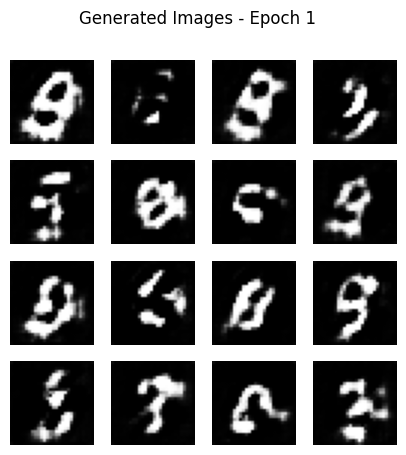

Epoch 2/10 | G Loss: 0.8022 | D Loss: 0.6480


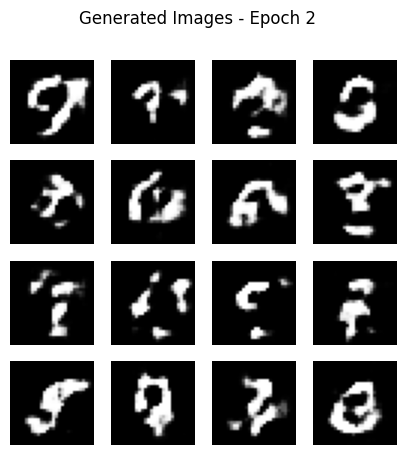

Epoch 3/10 | G Loss: 0.8778 | D Loss: 0.6072


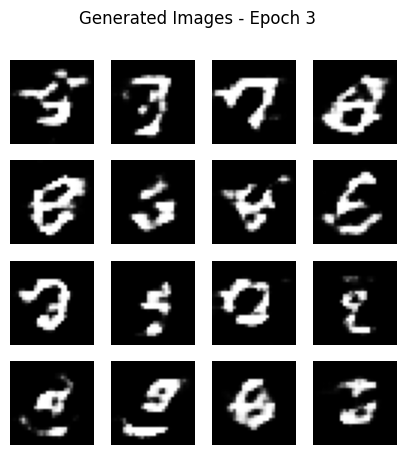

Epoch 4/10 | G Loss: 0.9738 | D Loss: 0.5663


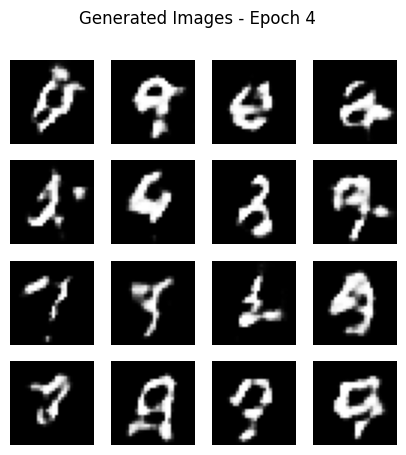

Epoch 5/10 | G Loss: 0.9782 | D Loss: 0.5788


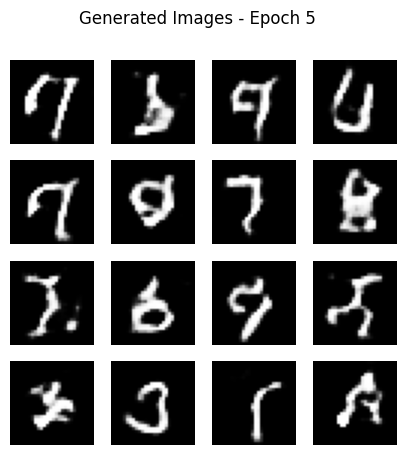

Epoch 6/10 | G Loss: 0.9207 | D Loss: 0.6068


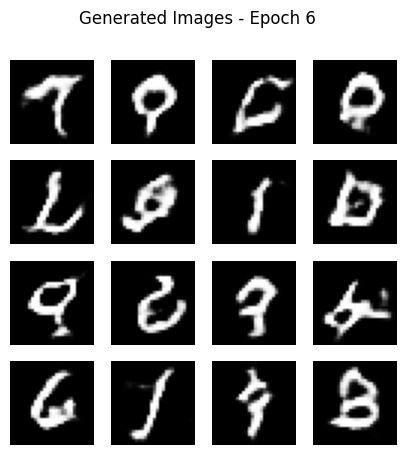

Epoch 7/10 | G Loss: 0.8909 | D Loss: 0.6202


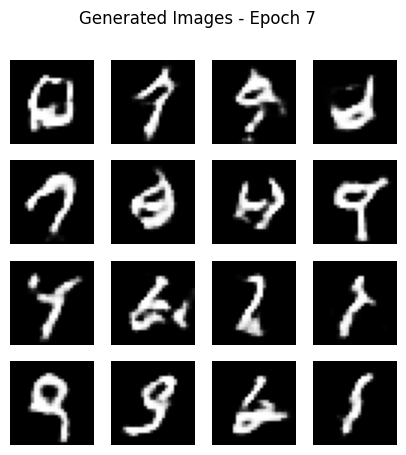

Epoch 8/10 | G Loss: 0.8756 | D Loss: 0.6282


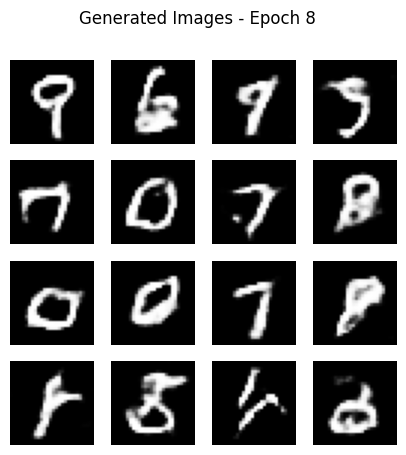

Epoch 9/10 | G Loss: 0.8634 | D Loss: 0.6318


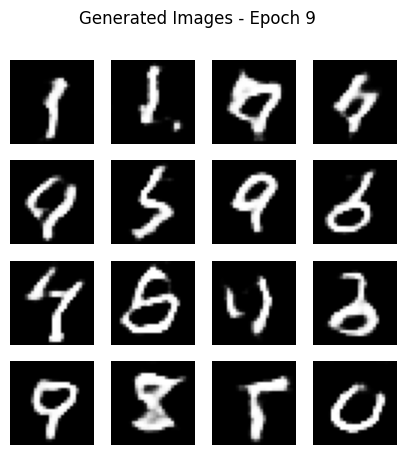

Epoch 10/10 | G Loss: 0.8616 | D Loss: 0.6298


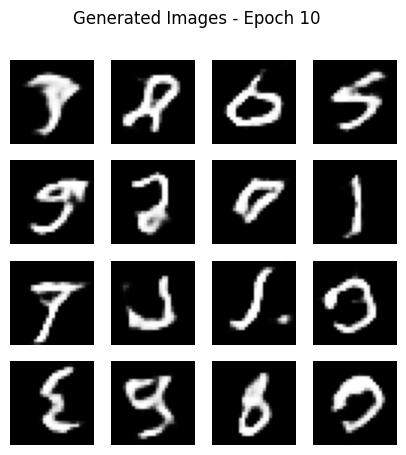

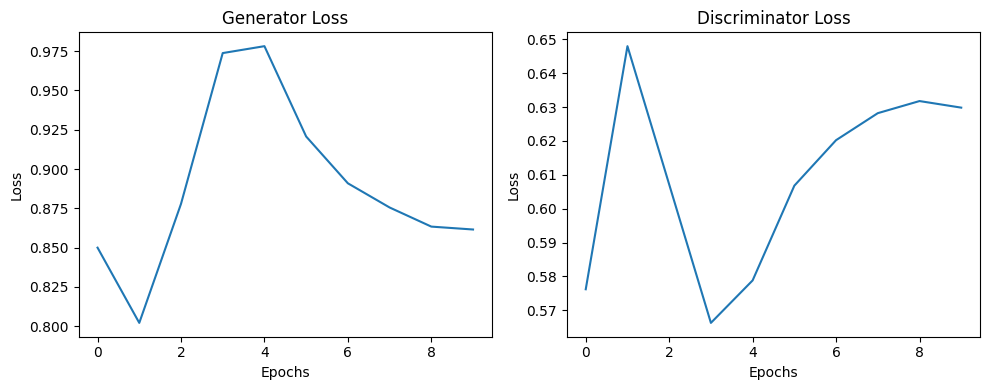

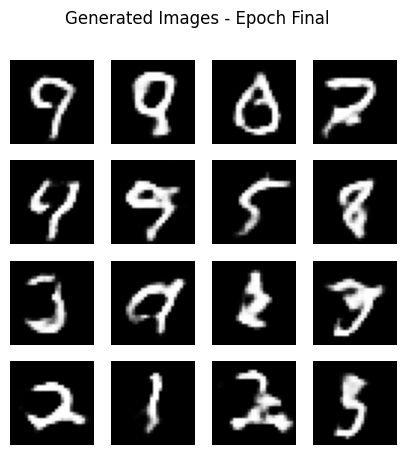

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt


(x, _), (_, _) = tf.keras.datasets.mnist.load_data()
x = (x.astype("float32") - 127.5) / 127.5
x = x.reshape(-1, 28, 28, 1)

dataset = tf.data.Dataset.from_tensor_slices(x).shuffle(60000).batch(128)


generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(100,)),
    tf.keras.layers.Dense(7*7*128),
    tf.keras.layers.Reshape((7,7,128)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2DTranspose(64, 4, strides=2, padding="same"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Conv2DTranspose(1, 4, strides=2, padding="same", activation="tanh")
])


discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)),
    tf.keras.layers.Conv2D(64, 4, strides=2, padding="same"),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Conv2D(128, 4, strides=2, padding="same"),
    tf.keras.layers.LeakyReLU(0.2),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1)
])


loss_fn = tf.keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)
d_opt = tf.keras.optimizers.Adam(0.0002, beta_1=0.5)


def train_step(real):
    noise = tf.random.normal([tf.shape(real)[0], 100])

    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake = generator(noise, training=True)
        real_out = discriminator(real, training=True)
        fake_out = discriminator(fake, training=True)

        g_loss = loss_fn(tf.ones_like(fake_out), fake_out)
        d_loss = (loss_fn(tf.ones_like(real_out), real_out) +
                  loss_fn(tf.zeros_like(fake_out), fake_out)) / 2

    gg = gt.gradient(g_loss, generator.trainable_variables)
    dg = dt.gradient(d_loss, discriminator.trainable_variables)

    g_opt.apply_gradients(zip(gg, generator.trainable_variables))
    d_opt.apply_gradients(zip(dg, discriminator.trainable_variables))

    return g_loss, d_loss


def show_images(epoch):
    noise = tf.random.normal([16, 100])
    images = generator(noise, training=False)
    plt.figure(figsize=(5,5))
    for i in range(16):
        plt.subplot(4,4,i+1)
        plt.imshow(images[i,:,:,0]*0.5+0.5, cmap="gray")
        plt.axis("off")
    plt.suptitle(f"Generated Images - Epoch {epoch}")
    plt.savefig(f"generated_{epoch}.png")
    plt.show()


gl, dl = [], []

for epoch in range(10):
    g_losses, d_losses = [], []

    for batch in dataset:
        g, d = train_step(batch)
        g_losses.append(g.numpy())
        d_losses.append(d.numpy())

    gl.append(np.mean(g_losses))
    dl.append(np.mean(d_losses))

    print(f"Epoch {epoch+1}/10 | G Loss: {gl[-1]:.4f} | D Loss: {dl[-1]:.4f}")
    show_images(epoch+1)


plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(gl)
plt.title("Generator Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.subplot(1,2,2)
plt.plot(dl)
plt.title("Discriminator Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.tight_layout()
plt.show()


show_images("Final")